<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw8/hw8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Diffusion Model: DDPM → DDIM on MNIST

This notebook implements a small denoising diffusion probabilistic model (DDPM, Ho et al. 2020) on MNIST and then swaps in the DDIM sampler (Song et al. 2021) without retraining.

| Setting | Value |
|---|---|
| Diffusion steps | $T = 100$ |
| Noise schedule | $\beta_t$ linear from $10^{-4}$ to $0.02$ |
| Batch size / epochs | 128 / 50 |
| Network | small U-Net-style CNN (ε-prediction), sinusoidal timestep embedding |

**Contents:** (a) forward diffusion · (b) training + loss plot · (c) DDPM sampling · (d) DDIM sampling and comparison · discussion.
On a T4, 50 epochs took about 53 minutes in our run.

**Indexing convention.** The paper indexes timesteps $t = 1,\dots,T$. In code we use 0-based indices `t = 0,…,T-1`, so code index `t` corresponds to paper timestep $t+1$.

In [1]:
import math, time, os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: cuda


## Configuration and noise schedule

$$\alpha_t = 1-\beta_t, \qquad \bar\alpha_t = \prod_{s=1}^{t}\alpha_s$$

In [2]:
T = 100
BETA_START, BETA_END = 1e-4, 0.02
BATCH_SIZE = 128
EPOCHS = 50
LR = 2e-4
CKPT_PATH = "ddpm_mnist.pt"

betas = torch.linspace(BETA_START, BETA_END, T, dtype=torch.float32)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = torch.cat([torch.ones(1), alpha_bars[:-1]])
# posterior variance  beta_tilde_t = (1 - abar_{t-1}) / (1 - abar_t) * beta_t
posterior_var = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)

betas, alphas, alpha_bars = betas.to(device), alphas.to(device), alpha_bars.to(device)
alpha_bars_prev, posterior_var = alpha_bars_prev.to(device), posterior_var.to(device)

print(f"alpha_bar_T          = {alpha_bars[-1].item():.4f}")
print(f"signal coeff sqrt(ab) = {alpha_bars[-1].sqrt().item():.4f}")
print(f"noise  coeff sqrt(1-ab)= {(1 - alpha_bars[-1]).sqrt().item():.4f}")

alpha_bar_T          = 0.3636
signal coeff sqrt(ab) = 0.6030
noise  coeff sqrt(1-ab)= 0.7978


**Note on this schedule.** With only $T=100$ steps and $\beta_T = 0.02$, $\bar\alpha_T \approx 0.36$, so $x_T = 0.60\,x_0 + 0.80\,\epsilon$: the final timestep still contains a lot of the image. The original DDPM used $T=1000$, where $\bar\alpha_T \approx 4\times10^{-5}$ and $x_T$ is essentially pure noise. Sampling here still starts from $x_T\sim\mathcal N(0,I)$, which does not exactly match what the network saw at $t=T$ during training. We keep the assigned schedule and come back to this in the discussion because it explains some of the sampler differences.

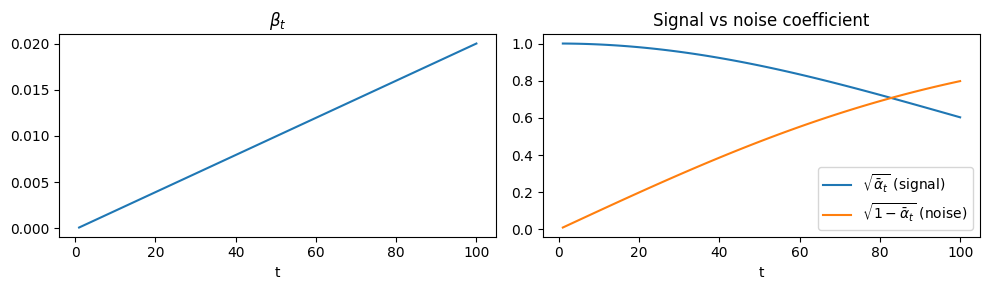

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ts = np.arange(1, T + 1)
ax[0].plot(ts, betas.cpu()); ax[0].set_title(r"$\beta_t$"); ax[0].set_xlabel("t")
ax[1].plot(ts, alpha_bars.sqrt().cpu(), label=r"$\sqrt{\bar\alpha_t}$ (signal)")
ax[1].plot(ts, (1 - alpha_bars).sqrt().cpu(), label=r"$\sqrt{1-\bar\alpha_t}$ (noise)")
ax[1].set_xlabel("t"); ax[1].legend(); ax[1].set_title("Signal vs noise coefficient")
plt.tight_layout(); plt.show()

## Data

MNIST images are scaled from $[0,1]$ to $[-1,1]$ so that data and noise live on comparable scales.

In [4]:
def scale_to_pm1(x):          # [0,1] -> [-1,1]  (named function so DataLoader workers can pickle it)
    return x * 2.0 - 1.0

transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(scale_to_pm1)])
train_set = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=(device.type == "cuda"), drop_last=True)
print(len(train_set), "training images,", len(train_loader), "batches/epoch")

def to_img(x):
    # [-1,1] -> [0,1] for display
    return ((x.clamp(-1, 1) + 1) / 2).cpu()

def show_grid(x, nrow=8, title=None, ax=None):
    grid = make_grid(to_img(x), nrow=nrow, padding=2, pad_value=1.0)
    if ax is None:
        plt.figure(figsize=(nrow * 0.9, (x.shape[0] // nrow) * 0.9))
        ax = plt.gca()
    ax.imshow(grid.permute(1, 2, 0)[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if title: ax.set_title(title)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.76MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 137kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.32MB/s]

60000 training images, 468 batches/epoch


## (a) Forward diffusion

Because a sum of Gaussians is Gaussian, the forward process can be sampled in closed form at any timestep:

$$q(x_t \mid x_0) = \mathcal N\!\left(x_t;\ \sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t) I\right)
\quad\Longleftrightarrow\quad
x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\ \ \epsilon\sim\mathcal N(0,I).$$

In [5]:
def q_sample(x0, t, noise=None):
    # Sample x_t ~ q(x_t | x_0). t: LongTensor of 0-based indices, shape (B,)
    if noise is None:
        noise = torch.randn_like(x0)
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

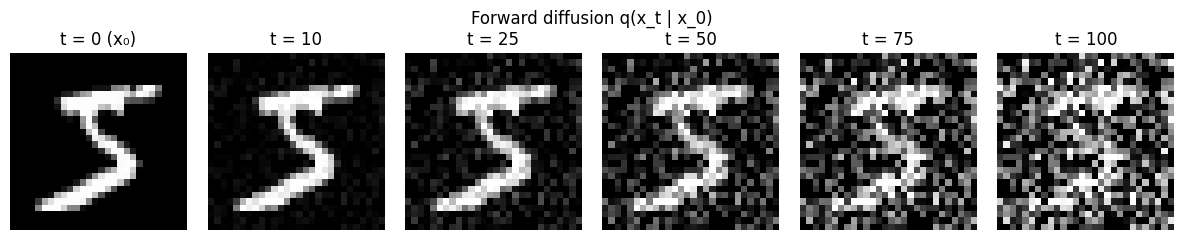

In [6]:
x0 = train_set[0][0].unsqueeze(0).to(device)          # one MNIST digit
show_steps = [0, 10, 25, 50, 75, 100]                  # paper timesteps (0 = clean image)
g = torch.Generator(device="cpu").manual_seed(1)
noise = torch.randn(x0.shape, generator=g).to(device)  # same noise for every t, so only the level changes

fig, axes = plt.subplots(1, len(show_steps), figsize=(2 * len(show_steps), 2.4))
for ax, s in zip(axes, show_steps):
    xt = x0 if s == 0 else q_sample(x0, torch.tensor([s - 1], device=device), noise)
    ax.imshow(to_img(xt)[0, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {s}" if s else "t = 0 (x₀)")
    ax.axis("off")
plt.suptitle("Forward diffusion q(x_t | x_0)")
plt.tight_layout(); plt.show()

The digit fades as noise grows. Because of the short schedule noted above, the digit is still faintly visible even at $t=T=100$.

## (b) Noise-prediction network

The network $\epsilon_\theta(x_t, t)$ is a small U-Net:

* **Timestep conditioning:** $t$ → sinusoidal embedding → 2-layer MLP; the result is projected and added to the feature maps inside every residual block.
* **Conv layers:** `conv_in`, two 3×3 convs per residual block (7 blocks), two stride-2 downsampling convs, two upsampling convs, 1×1 skip convs and `conv_out` — 22 convolutional layers in total, printed below (requirement: ≥ 4).
* **Nonlinearity:** SiLU (smooth ReLU variant) throughout.
* **Resolution path:** 28×28 → 14×14 → 7×7 → 14×14 → 28×28 with skip connections; output shape `(B, 1, 28, 28)` = input shape.

In [7]:
def timestep_embedding(t, dim):
    # Sinusoidal embedding of integer timesteps (Transformer-style).
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(F.silu(t_emb))[:, :, None, None]   # timestep conditioning
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class MiniUNet(nn.Module):
    def __init__(self, ch=64, t_dim=256):
        super().__init__()
        self.t_dim = t_dim
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))

        self.conv_in = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim)                          # 28x28
        self.pool1 = nn.Conv2d(ch, ch, 3, stride=2, padding=1)        # -> 14x14
        self.down2 = ResBlock(ch, 2 * ch, t_dim)                      # 14x14
        self.pool2 = nn.Conv2d(2 * ch, 2 * ch, 3, stride=2, padding=1)  # -> 7x7

        self.mid1 = ResBlock(2 * ch, 4 * ch, t_dim)                   # 7x7
        self.mid2 = ResBlock(4 * ch, 4 * ch, t_dim)

        self.up2 = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                 nn.Conv2d(4 * ch, 2 * ch, 3, padding=1))   # -> 14x14
        self.dec2 = ResBlock(4 * ch, 2 * ch, t_dim)                   # concat with skip
        self.up1 = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                 nn.Conv2d(2 * ch, ch, 3, padding=1))       # -> 28x28
        self.dec1 = ResBlock(2 * ch, ch, t_dim)

        self.norm_out = nn.GroupNorm(8, ch)
        self.conv_out = nn.Conv2d(ch, 1, 3, padding=1)

    def forward(self, x, t):
        t_emb = self.t_mlp(timestep_embedding(t, self.t_dim))
        h0 = self.conv_in(x)
        h1 = self.down1(h0, t_emb)
        h2 = self.down2(self.pool1(h1), t_emb)
        h = self.pool2(h2)
        h = self.mid2(self.mid1(h, t_emb), t_emb)
        h = self.dec2(torch.cat([self.up2(h), h2], dim=1), t_emb)
        h = self.dec1(torch.cat([self.up1(h), h1], dim=1), t_emb)
        return self.conv_out(F.silu(self.norm_out(h)))


model = MiniUNet().to(device)
n_conv = sum(isinstance(m, nn.Conv2d) for m in model.modules())
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M, conv layers: {n_conv}")
with torch.no_grad():
    test_x = torch.randn(4, 1, 28, 28, device=device)
    assert model(test_x, torch.randint(0, T, (4,), device=device)).shape == test_x.shape
print("output shape matches input shape ✓")

parameters: 3.92M, conv layers: 22
output shape matches input shape ✓


### Training objective

Sample $x_0$ from the data, $t\sim\text{Uniform}\{1,\dots,T\}$ and $\epsilon\sim\mathcal N(0,I)$, form $x_t$ with `q_sample`, and minimise the simplified DDPM loss

$$\mathcal L_\text{simple}(\theta) = \mathbb E_{x_0,t,\epsilon}\Big[\big\|\epsilon - \epsilon_\theta\big(\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\ t\big)\big\|^2\Big].$$

We also keep an exponential moving average (EMA) of the weights, a standard trick for diffusion models that gives noticeably cleaner samples; the EMA copy is used for sampling. The trained weights are saved to `ddpm_mnist.pt`, and re-running the notebook loads them instead of retraining.

In [8]:
import copy

ema_model = copy.deepcopy(model).eval()
for p in ema_model.parameters():
    p.requires_grad_(False)
EMA_DECAY = 0.999

@torch.no_grad()
def ema_update(ema, net, decay=EMA_DECAY):
    for pe, p in zip(ema.parameters(), net.parameters()):
        pe.mul_(decay).add_(p.detach(), alpha=1 - decay)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
step_losses, epoch_losses = [], []

if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device)
    model.load_state_dict(ckpt["model"]); ema_model.load_state_dict(ckpt["ema"])
    step_losses, epoch_losses = ckpt["step_losses"], ckpt["epoch_losses"]
    print(f"Loaded checkpoint from {CKPT_PATH} ({len(epoch_losses)} epochs). Delete it to retrain.")
else:
    t0 = time.time()
    for epoch in range(EPOCHS):
        model.train()
        running = 0.0
        for x0, _ in train_loader:
            x0 = x0.to(device, non_blocking=True)
            t = torch.randint(0, T, (x0.shape[0],), device=device)
            noise = torch.randn_like(x0)
            xt = q_sample(x0, t, noise)
            loss = F.mse_loss(model(xt, t), noise)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            ema_update(ema_model, model)

            step_losses.append(loss.item())
            running += loss.item()
        epoch_losses.append(running / len(train_loader))
        print(f"epoch {epoch + 1:2d}/{EPOCHS}  loss {epoch_losses[-1]:.4f}  ({time.time() - t0:.0f}s)")

    torch.save({"model": model.state_dict(), "ema": ema_model.state_dict(),
                "step_losses": step_losses, "epoch_losses": epoch_losses}, CKPT_PATH)

epoch  1/50  loss 0.1107  (64s)
epoch  2/50  loss 0.0681  (126s)
epoch  3/50  loss 0.0634  (190s)
epoch  4/50  loss 0.0611  (253s)
epoch  5/50  loss 0.0597  (315s)
epoch  6/50  loss 0.0587  (378s)
epoch  7/50  loss 0.0580  (442s)
epoch  8/50  loss 0.0573  (505s)
epoch  9/50  loss 0.0570  (568s)
epoch 10/50  loss 0.0566  (631s)
epoch 11/50  loss 0.0561  (694s)
epoch 12/50  loss 0.0557  (758s)
epoch 13/50  loss 0.0557  (821s)
epoch 14/50  loss 0.0554  (884s)
epoch 15/50  loss 0.0548  (948s)
epoch 16/50  loss 0.0548  (1011s)
epoch 17/50  loss 0.0546  (1075s)
epoch 18/50  loss 0.0544  (1138s)
epoch 19/50  loss 0.0540  (1202s)
epoch 20/50  loss 0.0545  (1265s)
epoch 21/50  loss 0.0537  (1329s)
epoch 22/50  loss 0.0535  (1392s)
epoch 23/50  loss 0.0537  (1456s)
epoch 24/50  loss 0.0537  (1519s)
epoch 25/50  loss 0.0536  (1583s)
epoch 26/50  loss 0.0531  (1647s)
epoch 27/50  loss 0.0531  (1710s)
epoch 28/50  loss 0.0534  (1774s)
epoch 29/50  loss 0.0530  (1837s)
epoch 30/50  loss 0.0527  (190

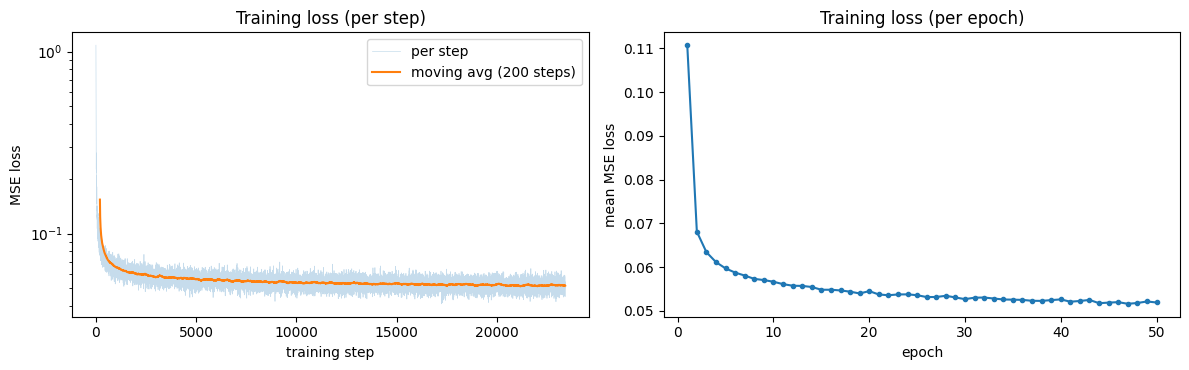

final epoch loss: 0.0519


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
steps = np.arange(len(step_losses))
w = 200
smooth = np.convolve(step_losses, np.ones(w) / w, mode="valid")
ax[0].plot(steps, step_losses, alpha=0.25, lw=0.5, label="per step")
ax[0].plot(steps[w - 1:], smooth, lw=1.5, label=f"moving avg ({w} steps)")
ax[0].set_yscale("log"); ax[0].set_xlabel("training step"); ax[0].set_ylabel("MSE loss")
ax[0].set_title("Training loss (per step)"); ax[0].legend()
ax[1].plot(np.arange(1, len(epoch_losses) + 1), epoch_losses, marker="o", ms=3)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean MSE loss"); ax[1].set_title("Training loss (per epoch)")
plt.tight_layout(); plt.show()
print(f"final epoch loss: {epoch_losses[-1]:.4f}")

The loss drops quickly in the first epoch (the network learns the gross statistics of the noise) and then decreases slowly. It never approaches zero: at small $t$ the image is almost clean and the added noise is a tiny, nearly unpredictable perturbation, so a residual error is irreducible. Per-step loss is noisy because each batch mixes random timesteps of very different difficulty.

## (c) DDPM sampling

Starting from $x_T\sim\mathcal N(0,I)$, iterate $t=T,\dots,1$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big) + \sigma_t z,\qquad z\sim\mathcal N(0,I),$$

with $z=0$ at the last step. We use the posterior variance $\sigma_t^2=\tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$ (the paper reports $\sigma_t^2=\beta_t$ works similarly). One network evaluation per step, so 100 evaluations.

In [10]:
@torch.no_grad()
def ddpm_sample(net, x_T):
    net.eval()
    x = x_T.clone()
    for t in reversed(range(T)):
        t_batch = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = net(x, t_batch)
        mean = (x - betas[t] / (1 - alpha_bars[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            x = mean + posterior_var[t].sqrt() * torch.randn_like(x)
        else:
            x = mean
    return x.clamp(-1, 1)

## (d) DDIM sampling

DDIM keeps the same trained network but uses a non-Markovian reverse process. At each step it first estimates the clean image

$$\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},$$

then jumps directly to an earlier timestep $s<t$ (not necessarily $t-1$):

$$x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s-\sigma^2}\;\epsilon_\theta(x_t,t) + \sigma z,\qquad
\sigma = \eta\sqrt{\frac{1-\bar\alpha_s}{1-\bar\alpha_t}}\sqrt{1-\frac{\bar\alpha_t}{\bar\alpha_s}}.$$

* $\eta = 0$ gives deterministic DDIM (used for the assignment): the same $x_T$ always maps to the same image.
* $\eta = 1$ with all $T$ steps recovers DDPM with $\sigma_t^2=\tilde\beta_t$, i.e. exactly the sampler in (c).
* With $S<T$ steps, we pick an evenly spaced sub-sequence $\tau_1<\dots<\tau_S$ of $\{1,\dots,T\}$; the final jump goes to $\bar\alpha_0 := 1$.

In [11]:
@torch.no_grad()
def ddim_sample(net, x_T, num_steps, eta=0.0):
    net.eval()
    taus = np.linspace(0, T - 1, num_steps).round().astype(int)   # 0-based, increasing
    assert len(np.unique(taus)) == num_steps
    x = x_T.clone()
    for i in reversed(range(num_steps)):
        t = int(taus[i])
        ab_t = alpha_bars[t]
        ab_s = alpha_bars[int(taus[i - 1])] if i > 0 else torch.tensor(1.0, device=device)
        t_batch = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = net(x, t_batch)
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        sigma = eta * ((1 - ab_s) / (1 - ab_t)).sqrt() * (1 - ab_t / ab_s).sqrt()
        dir_xt = (1 - ab_s - sigma ** 2).clamp(min=0).sqrt() * eps
        x = ab_s.sqrt() * x0_hat + dir_xt
        if eta > 0 and i > 0:
            x = x + sigma * torch.randn_like(x)
    return x.clamp(-1, 1)

print("DDIM timesteps (paper indexing), 20 steps:", (np.linspace(0, T - 1, 20).round().astype(int) + 1).tolist())

DDIM timesteps (paper indexing), 20 steps: [1, 6, 11, 17, 22, 27, 32, 37, 43, 48, 53, 58, 64, 69, 74, 79, 84, 90, 95, 100]


### Generate and compare

All samplers start from **the same** initial noise $x_T$, so the grids can be compared image by image. Wall-clock time and number of network evaluations (NFE) are recorded.

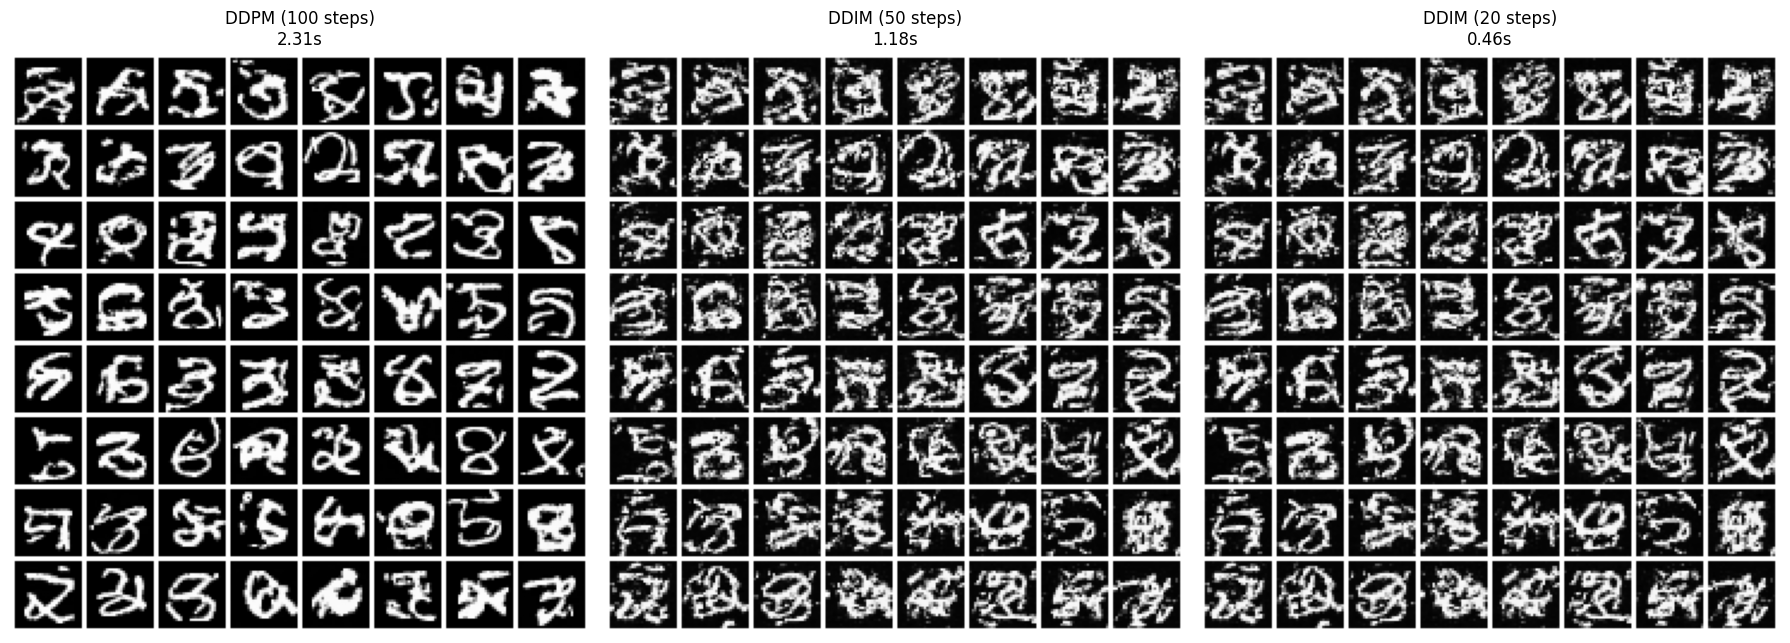

In [12]:
N_SAMPLES = 64
g = torch.Generator(device="cpu").manual_seed(42)
x_T = torch.randn(N_SAMPLES, 1, 28, 28, generator=g).to(device)

def timed(fn):
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time(); out = fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return out, time.time() - t0

torch.manual_seed(0)   # DDPM's per-step noise
samples, timings = {}, {}
samples["DDPM (100 steps)"], timings["DDPM (100 steps)"] = timed(lambda: ddpm_sample(ema_model, x_T))
samples["DDIM (50 steps)"],  timings["DDIM (50 steps)"]  = timed(lambda: ddim_sample(ema_model, x_T, 50))
samples["DDIM (20 steps)"],  timings["DDIM (20 steps)"]  = timed(lambda: ddim_sample(ema_model, x_T, 20))

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (name, x) in zip(axes, samples.items()):
    show_grid(x, nrow=8, ax=ax, title=f"{name}\n{timings[name]:.2f}s")
plt.tight_layout(); plt.show()

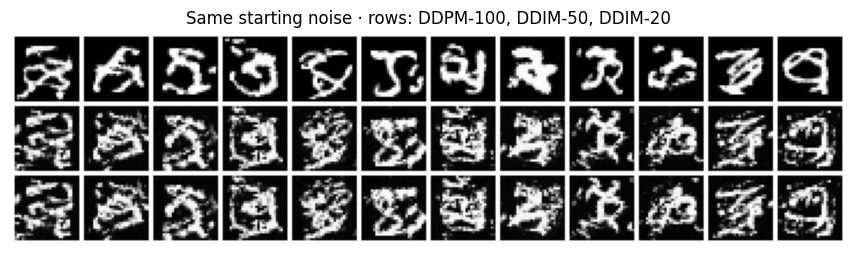

sampler             NFE  time (s)  speed-up
DDPM (100 steps)    100      2.31      1.0x
DDIM (50 steps)      50      1.18      2.0x
DDIM (20 steps)      20      0.46      5.0x

Mean |DDIM-50 − DDIM-20| per pixel (same x_T): 0.0073
Mean |DDPM − DDIM-50| per pixel (same x_T):    0.3161


In [13]:
# Side-by-side: same x_T, one row per sampler
k = 12
rows = torch.cat([samples[n][:k] for n in samples], dim=0)
plt.figure(figsize=(k * 0.9, 3 * 1.1))
show_grid(rows, nrow=k, ax=plt.gca())
plt.title("Same starting noise · rows: DDPM-100, DDIM-50, DDIM-20")
plt.show()

nfe = {"DDPM (100 steps)": 100, "DDIM (50 steps)": 50, "DDIM (20 steps)": 20}
d50, d20 = samples["DDIM (50 steps)"], samples["DDIM (20 steps)"]
print(f"{'sampler':<18}{'NFE':>5}{'time (s)':>10}{'speed-up':>10}")
for n in samples:
    print(f"{n:<18}{nfe[n]:>5}{timings[n]:>10.2f}{timings['DDPM (100 steps)'] / timings[n]:>9.1f}x")
print(f"\nMean |DDIM-50 − DDIM-20| per pixel (same x_T): {(d50 - d20).abs().mean().item():.4f}")
print(f"Mean |DDPM − DDIM-50| per pixel (same x_T):    {(samples['DDPM (100 steps)'] - d50).abs().mean().item():.4f}")

### Extra checks (optional)

1. **Determinism / consistency:** DDIM with $\eta=0$ is a fixed map from $x_T$ to $x_0$. Running it with 100, 50 and 20 steps from the same $x_T$ should give largely the same digits; only the fine detail changes.
2. **DDIM with $\eta=1$** over all 100 steps is mathematically the DDPM sampler; its samples should look statistically like the DDPM grid (individual images differ because the injected noise differs).

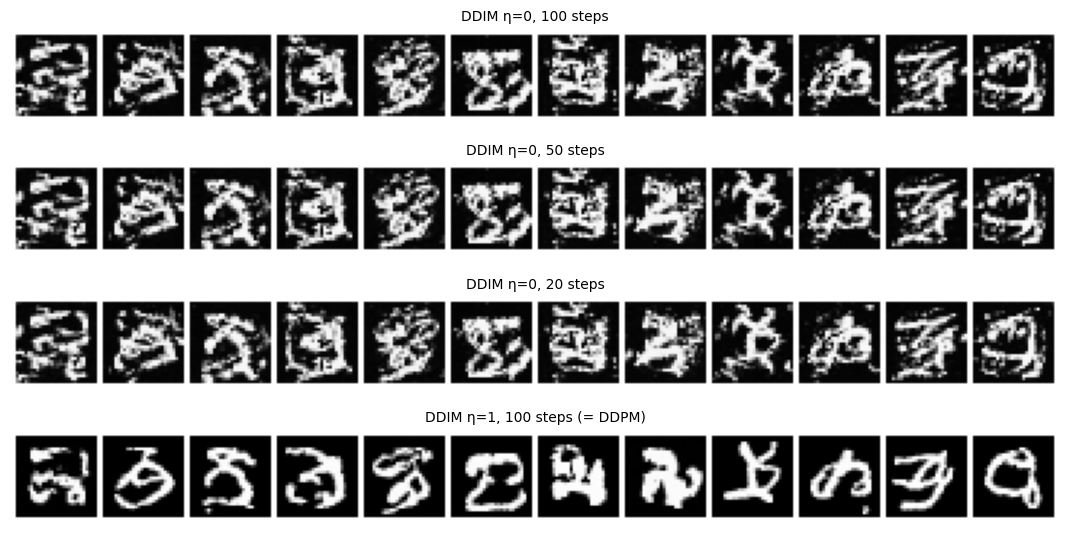

In [14]:
extra = {
    "DDIM η=0, 100 steps": ddim_sample(ema_model, x_T, 100, eta=0.0),
    "DDIM η=0, 50 steps": samples["DDIM (50 steps)"],
    "DDIM η=0, 20 steps": samples["DDIM (20 steps)"],
    "DDIM η=1, 100 steps (= DDPM)": ddim_sample(ema_model, x_T, 100, eta=1.0),
}
k = 12
fig, axes = plt.subplots(len(extra), 1, figsize=(k * 0.9, len(extra) * 1.4))
for ax, (name, x) in zip(axes, extra.items()):
    show_grid(x[:k], nrow=k, ax=ax); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

### Fixing the start distribution (no retraining)

The grids above show the effect predicted earlier. With this schedule, $\bar\alpha_T \approx 0.36$, so the network was trained on $x_T$ that still contains 60% of a mostly black image (MNIST's mean pixel in $[-1,1]$ is about $-0.74$). Pure $\mathcal N(0,I)$ noise has mean 0. To the network it looks like an image with far too much white, so it produces dense, scribbly strokes. Deterministic DDIM cannot correct this and gives speckled, cluttered digits. DDPM's injected noise corrects it only partly.

A 1-D simulation with an exact noise predictor and MNIST-like pixels (81% black, 19% white) shows the same thing. Starting from $\mathcal N(0,1)$, the samples have 28% white pixels with DDPM and 33% with DDIM-50/20. Starting from the matched distribution below, all three give 19%.

The fix keeps the assigned schedule and the trained weights and changes only the starting point. Using the per-pixel mean $\mu$ and variance $\sigma^2$ of the training set, we sample from a Gaussian approximation of the true $q(x_T)$:

$$x_T = \sqrt{\bar\alpha_T}\,\mu + \sqrt{\bar\alpha_T\,\sigma^2 + 1-\bar\alpha_T}\;z,\qquad z\sim\mathcal N(0,I).$$

The same $z$ as before is used, so the grids are directly comparable with the ones above. Only two summary images of the dataset ($\mu$ and $\sigma$) are used, never individual training images.

mean of x_T: N(0,I) start +0.003 | matched start -0.443


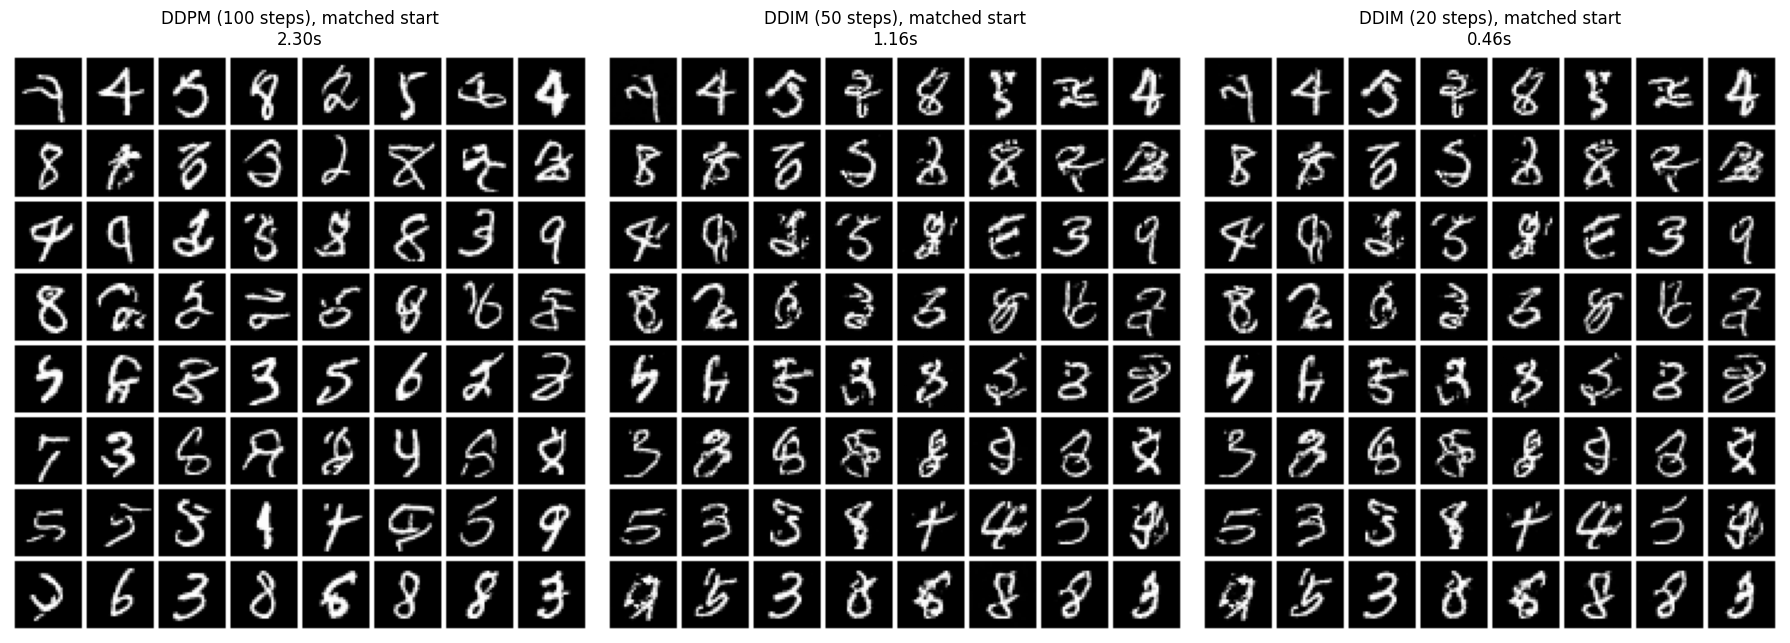

DDPM (100 steps)               fraction of white pixels (>0): 0.225
DDIM (50 steps)                fraction of white pixels (>0): 0.262
DDIM (20 steps)                fraction of white pixels (>0): 0.260
DDPM (100 steps) [matched]     fraction of white pixels (>0): 0.106
DDIM (50 steps) [matched]      fraction of white pixels (>0): 0.104
DDIM (20 steps) [matched]      fraction of white pixels (>0): 0.104
training data                  fraction of white pixels (>0): 0.132

Mean |DDIM-50 − DDIM-20| (matched start): 0.0033


In [15]:
data_x = train_set.data.float().div(255).mul(2).sub(1).unsqueeze(1)   # (60000,1,28,28) in [-1,1]
pix_mean = data_x.mean(0).to(device)
pix_var = data_x.var(0).to(device)
abT = alpha_bars[-1]

g = torch.Generator(device="cpu").manual_seed(42)
z = torch.randn(N_SAMPLES, 1, 28, 28, generator=g).to(device)        # identical to x_T used above
x_T_matched = abT.sqrt() * pix_mean + (abT * pix_var + 1 - abT).sqrt() * z
print(f"mean of x_T: N(0,I) start {x_T.mean().item():+.3f} | matched start {x_T_matched.mean().item():+.3f}")

torch.manual_seed(0)
samples_m, timings_m = {}, {}
samples_m["DDPM (100 steps)"], timings_m["DDPM (100 steps)"] = timed(lambda: ddpm_sample(ema_model, x_T_matched))
samples_m["DDIM (50 steps)"],  timings_m["DDIM (50 steps)"]  = timed(lambda: ddim_sample(ema_model, x_T_matched, 50))
samples_m["DDIM (20 steps)"],  timings_m["DDIM (20 steps)"]  = timed(lambda: ddim_sample(ema_model, x_T_matched, 20))

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (name, x) in zip(axes, samples_m.items()):
    show_grid(x, nrow=8, ax=ax, title=f"{name}, matched start\n{timings_m[name]:.2f}s")
plt.tight_layout(); plt.show()

for name, x in list(samples.items()) + [(n + " [matched]", v) for n, v in samples_m.items()]:
    print(f"{name:<30} fraction of white pixels (>0): {(x > 0).float().mean().item():.3f}")
print(f"{'training data':<30} fraction of white pixels (>0): {(data_x > 0).float().mean().item():.3f}")
d = samples_m
print(f"\nMean |DDIM-50 − DDIM-20| (matched start): {(d['DDIM (50 steps)'] - d['DDIM (20 steps)']).abs().mean().item():.4f}")

## Discussion

**What is the same.** All three samplers use the *same* trained network. DDPM and DDIM share the training objective and the marginals $q(x_t\mid x_0)$; DDIM only changes how the reverse process moves between timesteps. That is why no retraining was needed.

**Speed.** Cost is dominated by network evaluations: DDPM needs 100, DDIM-50 needs 50 and DDIM-20 needs 20, so DDIM-50 is about 2× and DDIM-20 about 5× faster (see the timing table). This is the main practical reason DDIM exists.

**Stochastic vs deterministic.** DDPM adds fresh Gaussian noise at every step, so the same $x_T$ gives a different digit each run, and the image identity is only loosely tied to $x_T$. DDIM with $\eta=0$ adds no noise: $x_T$ acts like a latent code, and the DDIM-50 and DDIM-20 rows produce largely the *same* digits with the same style (the small per-pixel difference between them, printed above, quantifies this). DDPM samples generally look different from the DDIM ones even from the same $x_T$.

**Quality vs number of steps.** DDPM's Markov chain is derived for step size 1; it cannot simply skip steps. DDIM's update is valid for any sub-sequence, because it moves along the predicted $\hat x_0$ direction instead of taking a small Gaussian step. In principle, larger jumps at 20 steps leave errors in $\epsilon_\theta$ less corrected. In this run, however, DDIM-20 was visually indistinguishable from DDIM-50: with only $T=100$ to begin with, 20 steps is a modest 5× reduction.

**Effect of this schedule.** As computed at the top, $\bar\alpha_T\approx0.36$, so during training the network never saw pure noise at $t=T$, yet sampling starts from $\mathcal N(0,I)$. DDPM's injected noise at every step partially "re-mixes" the trajectory and corrects this mismatch; deterministic DDIM cannot, because its output is a fixed function of the slightly wrong $x_T$. In a 1-D sanity check with an exact noise predictor (Gaussian data $\mathcal N(0.5, 0.3^2)$), DDPM recovered the target mean to within about 0.03 from $\mathcal N(0,1)$ initial noise, while DDIM's mean was off by about 0.1 and its spread was inflated. Using $T=1000$, or rescaling the schedule so $\bar\alpha_T\approx0$ (e.g. $\beta_\text{end}=0.2$ for $T=100$), would remove this effect; the matched-start section above fixes it without retraining.

**Observations from this run** (T4 GPU, 50 epochs, final loss 0.052).
- **Training:** the loss fell from 0.111 in epoch 1 to 0.068 in epoch 2. It then improved slowly to 0.052 by epoch 50 and had nearly plateaued.
- **DDPM (100 steps):** the background is clean and black, with smooth, thick white strokes. Most samples are digit-like (loops and curves resembling 2, 3, 5, 6, 8, 0), but many are scribbles rather than clearly readable digits. They tend to have too much ink, which is the start-distribution effect described above.
- **DDIM (50 steps):** the same overall stroke layout as DDIM-20, but much noisier than DDPM, with salt-and-pepper speckle and cluttered backgrounds. They are visibly worse than DDPM.
- **DDIM (20 steps):** almost identical to DDIM-50. The mean per-pixel difference from the same $x_T$ is only 0.0073, against 0.316 between DDPM and DDIM-50. Deterministic DDIM maps a given $x_T$ to essentially the same image whether it takes 20, 50 or 100 steps, and going from 50 to 20 steps cost no visible quality.
- **η = 1 check:** DDIM with $\eta=1$ over 100 steps gives clean samples of the same kind as DDPM. This confirms that the gap between DDPM and DDIM comes from the stochastic vs deterministic update and not from a bug.
- **Timing:** DDPM 2.31 s, DDIM-50 1.18 s (2.0× faster), DDIM-20 0.46 s (5.0× faster), for 64 images.
- **Matched start (extra section above):** changing only the starting noise (same network, same $z$) gives a large improvement for all three samplers.
  - *DDPM:* most samples are now clearly readable digits (4, 5, 8, 9, 3, 6, 7 …) on a clean background, with thinner, more natural strokes. A few are still malformed.
  - *DDIM-50 / DDIM-20:* the salt-and-pepper speckle is gone and most samples are recognizable digits. Strokes are a little thinner and more fragmented than DDPM's. DDIM-20 is again almost identical to DDIM-50 (mean difference 0.0033), so 20 steps lost no visible quality.
  - *Ink amount:* the white-pixel fraction went from 0.225 (DDPM) and 0.26 (DDIM) with $\mathcal N(0,I)$ to about 0.105 for all three samplers, against 0.132 in the training data. It now slightly undershoots, probably because the per-pixel Gaussian ignores correlations between pixels, but it is far closer than before and DDPM and DDIM now agree.

**Summary.** DDIM replaces DDPM's stochastic, step-by-step denoising with a deterministic, step-skipping update that uses the same network. It was 2× (50 steps) and 5× (20 steps) faster, and DDIM-20 matched DDIM-50 almost exactly. With the assigned schedule the final timestep is still 60% image, so starting from $\mathcal N(0,I)$ is out of distribution. That hurt deterministic DDIM (speckled, cluttered samples) much more than DDPM, whose injected noise partly corrects the mismatch. Starting instead from a Gaussian approximation of $q(x_T)$, with no retraining, gave readable digits from all three samplers. The remaining difference between DDPM and DDIM is small: DDPM's strokes are slightly smoother, while DDIM is much faster.